# 02 · Organización espacial y temporal de MODIS y VIIRS
Avance del proyecto: 50 %. La armonización estadística sigue pendiente.
Ejecutar después de 01. Piloto aprobado: Aqua y Suomi NPP, SP 2013–2025,
type=0 (presunto fuego de vegetación). No se filtra confianza.
Se exploran 5, 10 y 25 km en LAEA local y semanas lunes-domingo UTC.
La elección de escala y las particiones de evaluación siguen propuestas.
Referencias: https://shapely.readthedocs.io/en/stable/strtree.html
y https://pyproj4.github.io/pyproj/stable/api/transformer.html

## Configuración de rutas
Ejecutar los notebooks en orden. No se requieren scripts externos del proyecto.
Los ZIP originales deben estar en INPUT_DIR; editar esa variable si corresponde.
Los resultados se generan en artifacts/, fuera de los notebooks.
Dependencias: pandas, numpy, matplotlib, pyproj y shapely.
Instalar si faltan: %pip install pandas numpy matplotlib pyproj shapely
REUSE_CACHE=False recalcula los resultados. La entrega se ejecutó con caché
previamente verificado por hashes y controles de conservación de filas.

In [1]:
import os
from pathlib import Path
REPO_ROOT = Path.cwd().resolve()
if REPO_ROOT.name == 'notebooks':
    REPO_ROOT = REPO_ROOT.parent
INPUT_DIR = Path(os.environ.get('FIRMS_INPUT_DIR', str(Path.home() / 'Downloads')))
ARTIFACTS = Path(os.environ.get('FIRMS_ARTIFACTS_DIR', str(REPO_ROOT / 'artifacts')))
REUSE_CACHE = os.environ.get('FIRMS_REUSE_CACHE', '0') == '1'

In [2]:
from pathlib import Path

In [3]:
import argparse

In [4]:
import hashlib

In [5]:
import json

In [6]:
import platform as runtime_platform

In [7]:
import numpy as np

In [8]:
import pandas as pd

In [9]:
import pyproj

In [10]:
import shapely

In [11]:
from pyproj import CRS, Transformer

In [12]:
from shapely import STRtree, box, points

In [13]:
CRS_LOCAL = '+proj=laea +lat_0=-9 +lon_0=-75 +datum=WGS84 +units=m +no_defs'

In [14]:
SIZES = (5000, 10000, 25000)

In [15]:
GZIP = {'method': 'gzip', 'compresslevel': 1, 'mtime': 0}

In [16]:
COLS = ['source_member', 'source_row', 'timestamp_utc', 'platform', 'processing',
        'instrument_normalized', 'latitude_deg', 'longitude_deg', 'frp_mw',
        'hotspot_type_code', 'candidate_confidence_filter', 'flag_invalid_datetime',
        'flag_invalid_coordinates', 'flag_invalid_confidence', 'flag_invalid_frp']

Implementación reproducible: `sha256`.

In [17]:
def sha256(path):
    h = hashlib.sha256()
    with path.open('rb') as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()

Implementación reproducible: `assign_cells`.

In [18]:
def assign_cells(x, y, size):
    # Intervalos semiabiertos: borde oeste/sur incluido; este/norte excluido.
    return np.floor(np.asarray(x) / size).astype('int64'), np.floor(
        np.asarray(y) / size).astype('int64')

Implementación reproducible: `query_owned_cells`.

In [19]:
def query_owned_cells(tree, cells, xy):
    """R-tree busca candidatos; regla semiabierta resuelve puntos en límites."""
    hits = tree.query(points(xy[:, 0], xy[:, 1]), predicate='intersects')
    p, c = hits
    bounds = cells[['xmin_m', 'ymin_m', 'xmax_m', 'ymax_m']].to_numpy()[c]
    selected = ((xy[p, 0] >= bounds[:, 0]) & (xy[p, 0] < bounds[:, 2])
                & (xy[p, 1] >= bounds[:, 1]) & (xy[p, 1] < bounds[:, 3]))
    p, c = p[selected], c[selected]
    order = np.argsort(p)
    assert np.array_equal(p[order], np.arange(len(xy))), 'Asignación no única.'
    return cells.cell_id.to_numpy()[c[order]]

Implementación reproducible: `split_labels`.

In [20]:
def split_labels(weeks):
    ends = weeks + pd.Timedelta(days=7)
    labels = pd.Series('boundary_week', index=weeks.index, dtype='string')
    for label, start, stop in [
        ('development', '2013-01-01', '2022-01-01'),
        ('validation', '2022-01-01', '2024-01-01'),
        ('test', '2024-01-01', '2026-01-01'),
    ]:
        labels.loc[(weeks >= pd.Timestamp(start, tz='UTC'))
                   & (ends <= pd.Timestamp(stop, tz='UTC'))] = label
    return labels

Implementación reproducible: `load_pilot`.

In [21]:
def load_pilot(root):
    collected, accounting, hashes = [], [], []
    for stem in ['fire_archive_M-C61_848898', 'fire_archive_SV-C2_848901']:
        source = root / 'datos_normalizados' / f'{stem}_normalized.csv.gz'
        hashes.append({'file': str(source.resolve()), 'sha256': sha256(source)})
        df = pd.read_csv(source, usecols=COLS, dtype={
            'source_member': 'string', 'platform': 'string', 'processing': 'string'})
        df['timestamp_utc'] = pd.to_datetime(df.timestamp_utc, utc=True, errors='raise')
        scope = (df.processing.eq('SP') & df.platform.isin(['Aqua', 'Suomi-NPP'])
                 & df.timestamp_utc.dt.year.between(2013, 2025))
        vegetation = df.hotspot_type_code.eq(0)
        invalid = df[[c for c in COLS if c.startswith('flag_invalid_')]].any(axis=1)
        assert not invalid[scope].any(), 'Hay filas inválidas en el piloto: revisar antes de continuar.'
        accounting.append({'file': source.name, 'input_rows': len(df),
                           'pilot_before_type': int(scope.sum()),
                           'pilot_type0_rows': int((scope & vegetation).sum()),
                           'pilot_other_types': int((scope & ~vegetation).sum())})
        collected.append(df.loc[scope & vegetation].copy())
    data = pd.concat(collected, ignore_index=True)
    assert not data.duplicated(['source_member', 'source_row']).any()
    assert data.candidate_confidence_filter.isin([True, False]).all()
    data['week_start_utc'] = (data.timestamp_utc.dt.normalize()
                              - pd.to_timedelta(data.timestamp_utc.dt.dayofweek, unit='D'))
    data['date_utc'] = data.timestamp_utc.dt.normalize()
    data['split_proposed'] = split_labels(data.week_start_utc)
    return data, accounting, hashes

Implementación reproducible: `aggregate`.

In [22]:
def aggregate(data, size, out, transformer_inverse):
    km = size // 1000
    col = f'cell_id_{km}km'
    cx, cy = assign_cells(data.x_m, data.y_m, size)
    data[col] = [f'laea{km}_{a}_{b}' for a, b in zip(cx, cy)]
    cells = pd.DataFrame({'cell_id': data[col], 'ix': cx, 'iy': cy}).drop_duplicates()
    cells = cells.sort_values(['ix', 'iy']).reset_index(drop=True)
    cells['xmin_m'], cells['ymin_m'] = cells.ix * size, cells.iy * size
    cells['xmax_m'], cells['ymax_m'] = cells.xmin_m + size, cells.ymin_m + size
    lon, lat = transformer_inverse.transform(cells.xmin_m + size / 2, cells.ymin_m + size / 2)
    cells['center_lon'], cells['center_lat'] = lon, lat
    cells['nominal_area_km2'] = km * km
    cells.to_csv(out / f'celdas_activas_{km}km.csv.gz', index=False, compression=GZIP)
    grouped = data.groupby([col, 'week_start_utc', 'platform', 'split_proposed'], observed=True)
    weekly = grouped.agg(
        n_detections=('source_row', 'size'),
        n_confidence_candidate=('candidate_confidence_filter', 'sum'),
        sum_observed_frp_mw=('frp_mw', 'sum'),
        mean_observed_frp_mw=('frp_mw', 'mean'),
        n_detection_dates=('date_utc', 'nunique'),
    ).reset_index().rename(columns={col: 'cell_id'})
    assert int(weekly.n_detections.sum()) == len(data)
    assert int(weekly.n_confidence_candidate.sum()) == int(data.candidate_confidence_filter.sum())
    assert np.isclose(weekly.sum_observed_frp_mw.sum(), data.frp_mw.sum())
    weekly.to_csv(out / f'conteos_semanales_{km}km.csv.gz', index=False, compression=GZIP)
    # Diagnóstico de escala solo en desarrollo. Ausencias de plataforma quedan NA.
    dev = weekly.loc[weekly.split_proposed.eq('development')]
    pivot = dev.pivot(index=['cell_id', 'week_start_utc'], columns='platform', values='n_detections')
    both = pivot.notna().all(axis=1)
    stats = {'grid_km': km, 'area_km2': km * km,
             'cells_all_years': len(cells), 'development_active_cell_weeks': len(pivot),
             'development_both_detected_cell_weeks': int(both.sum()),
             'development_both_fraction': float(both.mean())}
    for name, group in dev.groupby('platform'):
        stats[f'{name}_median_count'] = float(group.n_detections.median())
        stats[f'{name}_singleton_fraction'] = float(group.n_detections.eq(1).mean())
    # Verificación geométrica independiente: R-tree frente a asignación aritmética.
    geoms = box(cells.xmin_m.to_numpy(), cells.ymin_m.to_numpy(),
                cells.xmax_m.to_numpy(), cells.ymax_m.to_numpy())
    tree = STRtree(geoms)
    sample = data.sample(min(2000, len(data)), random_state=42)
    indexed = query_owned_cells(tree, cells, sample[['x_m', 'y_m']].to_numpy())
    assert np.array_equal(indexed, sample[col].to_numpy())
    # Incluye bordes exactos y coordenadas negativas.
    bxy = cells[['xmin_m', 'ymin_m']].head(20).to_numpy()
    expected = cells.cell_id.head(20).to_numpy()
    assert np.array_equal(query_owned_cells(tree, cells, bxy), expected)
    stats['rtree_verified_sample_points'] = len(sample)
    stats['rtree_verified_boundary_points'] = len(bxy)
    return stats

Implementación reproducible: `run`.

In [23]:
def run(source, out):
    out.mkdir(parents=True, exist_ok=True)
    data, accounting, hashes = load_pilot(source)
    print(f'Piloto type=0: {len(data):,} detecciones', flush=True)
    crs = CRS.from_proj4(CRS_LOCAL)
    forward = Transformer.from_crs('EPSG:4326', crs, always_xy=True)
    inverse = Transformer.from_crs(crs, 'EPSG:4326', always_xy=True)
    data['x_m'], data['y_m'] = forward.transform(data.longitude_deg, data.latitude_deg)
    assert np.isfinite(data[['x_m', 'y_m']].to_numpy()).all()
    lon, lat = inverse.transform(data.x_m, data.y_m)
    assert np.allclose(lon, data.longitude_deg, atol=1e-7, rtol=0)
    assert np.allclose(lat, data.latitude_deg, atol=1e-7, rtol=0)
    assert data.week_start_utc.dt.dayofweek.eq(0).all()
    assert (data.timestamp_utc >= data.week_start_utc).all()
    assert (data.timestamp_utc < data.week_start_utc + pd.Timedelta(days=7)).all()
    checks = []
    for size in SIZES:
        checks.append(aggregate(data, size, out, inverse))
        print(f'Malla {size//1000} km: agregación y R-tree verificados', flush=True)
    keep = ['source_member', 'source_row', 'timestamp_utc', 'platform', 'week_start_utc',
            'split_proposed', 'x_m', 'y_m', 'cell_id_5km', 'cell_id_10km', 'cell_id_25km']
    data[keep].to_csv(out / 'asignacion_puntos.csv.gz', index=False, compression=GZIP)
    stats = pd.DataFrame(checks)
    stats.to_csv(out / 'comparacion_escalas_desarrollo.csv', index=False)
    pd.DataFrame(accounting).to_csv(out / 'flujo_seleccion.csv', index=False)
    (out / 'crs_local.wkt').write_text(crs.to_wkt(), encoding='utf-8')
    manifest = {
        'progress_percent': 50, 'harmonized': False, 'rows_pilot_type0': len(data),
        'pilot_rows_by_platform': {k: int(v) for k, v in data.platform.value_counts().items()},
        'confidence_filtered': False, 'zero_frp_retained': int(data.frp_mw.eq(0).sum()),
        'source_hashes': hashes, 'grid_origin_m': [0, 0], 'grid_sizes_m': SIZES,
        'crs_proj': CRS_LOCAL, 'week': 'UTC Monday 00:00 inclusive to next Monday exclusive',
        'missing_policy': 'Sparse positive detections only; absent platform/cell/week is unknown, not confirmed zero.',
        'split_status': 'Proposed, pending human review before fitting.',
        'development': '2013-2021', 'validation': '2022-2023', 'test': '2024-2025',
        'boundary_weeks': 'Preserved in exports; excluded from split diagnostics/evaluation.',
        'spatial_extent': 'Cells containing downloaded Peru detections; no national polygon clipping.',
        'rtree': 'Shapely STRtree rebuilt from cell bounds; 2000 sampled points and 20 boundary points per grid.',
        'versions': {'python': runtime_platform.python_version(), 'pandas': pd.__version__,
                     'numpy': np.__version__, 'pyproj': pyproj.__version__, 'shapely': shapely.__version__},
        'checks': checks,
    }
    (out / 'manifest.json').write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding='utf-8')
    print(stats.to_string(index=False), flush=True)

## Ejecutar construcción o verificar caché

In [24]:
SOURCE_DIR = ARTIFACTS / '02_preparacion'
OUTPUT_DIR = ARTIFACTS / '03_espacio_tiempo'
if REUSE_CACHE:
    cached = json.loads((OUTPUT_DIR / 'manifest.json').read_text(encoding='utf-8'))
    for entry in cached['source_hashes']:
        original_name = entry['file'].replace('\\', '/').split('/')[-1]
        assert sha256(SOURCE_DIR / 'datos_normalizados' / original_name) == entry['sha256']
    for km in (5, 10, 25):
        counts = pd.read_csv(OUTPUT_DIR / f'conteos_semanales_{km}km.csv.gz')
        assert counts.n_detections.sum() == cached['rows_pilot_type0']
        assert not counts.duplicated(['cell_id', 'week_start_utc', 'platform']).any()
    print('Caché verificado: hashes de entradas y conteos por escala.')
else:
    run(SOURCE_DIR, OUTPUT_DIR)

Caché verificado: hashes de entradas y conteos por escala.


## Verificar nuevamente el R-tree
Se reconstruye el índice; se consultan 2.000 detecciones reales elegidas al azar
del piloto mixto y 20 puntos sintéticos situados en los bordes por escala.
Los puntos de muestra no representan 2.000 detecciones por sensor.

In [25]:
assigned = pd.read_csv(OUTPUT_DIR / 'asignacion_puntos.csv.gz')
sample = assigned.sample(2000, random_state=42)
for km in (5, 10, 25):
    cells = pd.read_csv(OUTPUT_DIR / f'celdas_activas_{km}km.csv.gz')
    tree = STRtree(box(cells.xmin_m.to_numpy(), cells.ymin_m.to_numpy(),
                      cells.xmax_m.to_numpy(), cells.ymax_m.to_numpy()))
    found = query_owned_cells(tree, cells, sample[['x_m', 'y_m']].to_numpy())
    assert np.array_equal(found, sample[f'cell_id_{km}km'].to_numpy())
    corners = cells[['xmin_m', 'ymin_m']].head(20).to_numpy()
    assert np.array_equal(query_owned_cells(tree, cells, corners), cells.cell_id.head(20))
    print(f'{km} km: 2.000 detecciones y 20 puntos de borde, asignación correcta.')

5 km: 2.000 detecciones y 20 puntos de borde, asignación correcta.
10 km: 2.000 detecciones y 20 puntos de borde, asignación correcta.
25 km: 2.000 detecciones y 20 puntos de borde, asignación correcta.


# FIRMS Perú: zonas y semanas comunes
Avance 50 %. Se aplicó el filtro aprobado `type=0`; no se filtró por confianza.
Se comparan 5, 10 y 25 km. No hay datos armonizados ni modelos ajustados.

In [26]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
root = OUTPUT_DIR
m = json.loads((root / 'manifest.json').read_text(encoding='utf-8'))
stats = pd.read_csv(root / 'comparacion_escalas_desarrollo.csv')
flow = pd.read_csv(root / 'flujo_seleccion.csv')
print('Filas del piloto:', f"{m['rows_pilot_type0']:,}")
print('Por plataforma:', m['pilot_rows_by_platform'])
display(flow)

Filas del piloto: 1,097,469
Por plataforma: {'Suomi-NPP': 941604, 'Aqua': 155865}


,file,input_rows,pilot_before_type,pilot_type0_rows,pilot_other_types
0,fire_archive_M-C61_848898_normalized.csv.gz,362159,158674,155865,2809
1,fire_archive_SV-C2_848901_normalized.csv.gz,1058423,966592,941604,24988


## Espacio y tiempo
Malla de igual área en proyección LAEA local, origen común (0,0).
Semana: lunes a domingo UTC. Celdas semiabiertas, sin asignación doble en bordes.
Los tamaños son del plano proyectado, no distancias geodésicas exactas.
Los archivos de celdas muestran actividad descargada; no cobertura de todo Perú.

In [27]:
display(stats.round(4))
assert m['harmonized'] is False
assert flow.pilot_type0_rows.sum() == m['rows_pilot_type0']
assert stats.rtree_verified_sample_points.eq(2000).all()
assert stats.rtree_verified_boundary_points.eq(20).all()

,grid_km,area_km2,cells_all_years,development_active_cell_weeks,development_both_detected_cell_weeks,development_both_fraction,Aqua_median_count,Aqua_singleton_fraction,Suomi-NPP_median_count,Suomi-NPP_singleton_fraction,rtree_verified_sample_points,rtree_verified_boundary_points
0,5,25,24946,331960,48675,0.1466,1.0,0.6931,1.0,0.5709,2000,20
1,10,100,8749,233302,45287,0.1941,1.0,0.5878,2.0,0.4795,2000,20
2,25,625,1970,124477,32201,0.2587,2.0,0.4709,2.0,0.3767,2000,20


## Comparación de escalas
Diagnósticos calculados solo con semanas completas de desarrollo 2013–2021.
Co-detección significa detecciones de ambas plataformas en una celda-semana;
no significa mismo incendio ni observación simultánea. Más co-detección a
mayor escala es esperable por agregación y no prueba una mejor armonización.

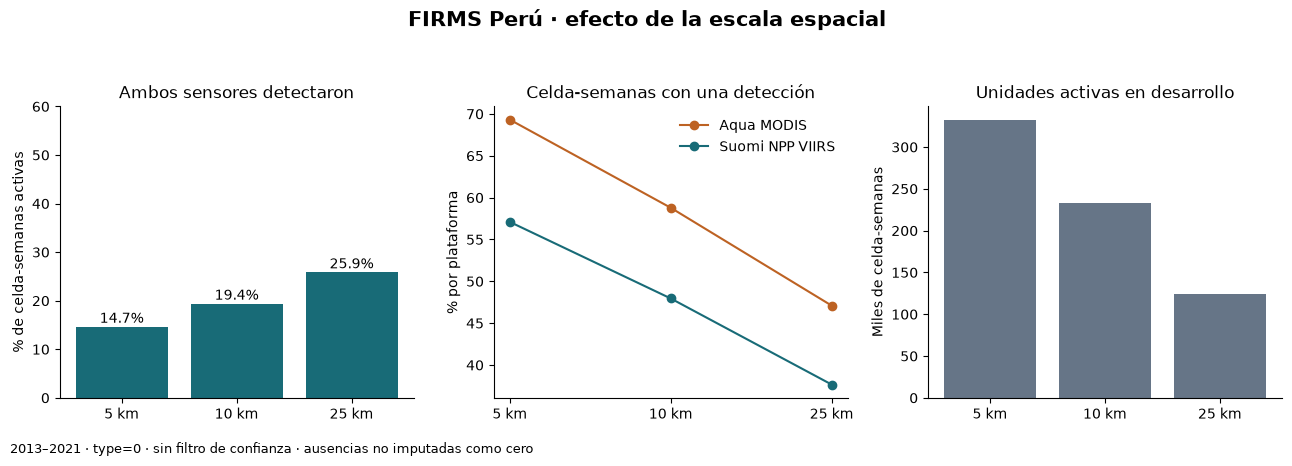

In [28]:
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10})
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
labels = stats.grid_km.astype(str) + ' km'
color = '#186b77'
axes[0].bar(labels, stats.development_both_fraction * 100, color=color)
axes[0].set(ylabel='% de celda-semanas activas', title='Ambos sensores detectaron')
for i, value in enumerate(stats.development_both_fraction * 100):
    axes[0].text(i, value + 0.8, f'{value:.1f}%', ha='center')
axes[0].set_ylim(0, max(60, stats.development_both_fraction.max()*115))
x = range(len(stats))
axes[1].plot(x, stats.Aqua_singleton_fraction*100, 'o-', label='Aqua MODIS', color='#bd6223')
axes[1].plot(x, stats['Suomi-NPP_singleton_fraction']*100, 'o-', label='Suomi NPP VIIRS', color=color)
axes[1].set(xticks=list(x), xticklabels=labels, ylabel='% por plataforma',
            title='Celda-semanas con una detección')
axes[1].legend(frameon=False)
axes[2].bar(labels, stats.development_active_cell_weeks/1000, color='#667587')
axes[2].set(ylabel='Miles de celda-semanas', title='Unidades activas en desarrollo')
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('FIRMS Perú · efecto de la escala espacial', fontsize=15, fontweight='bold')
fig.text(0.01, 0.015, '2013–2021 · type=0 · sin filtro de confianza · ausencias no imputadas como cero', fontsize=9)
fig.tight_layout(rect=(0, 0.05, 1, 0.93))
plt.show()

Las celdas más grandes reúnen más actividad y reducen detalle local. Elegir
una escala implica equilibrar soporte de datos y utilidad geográfica.
Las mallas no corrigen sensibilidad, horarios, nubes ni oportunidades de detección.

## Evaluación propuesta y limitaciones
Desarrollo: 2013–2021. Validación: 2022–2023. Prueba: 2024–2025.
Semanas en límites de bloques: preservadas, excluidas de la evaluación propuesta.
El corte y la escala requieren revisión humana antes de ajustar modelos.
No se conoce exposición observacional de cada celda ni se generan ceros confirmados.
Entrenar solo con co-detecciones positivas introduciría selección; debe resolverse
en el diseño del método. Aún no hay baseline, modelo ni métrica de armonización.